In [32]:
import plotly as pl
import matplotlib.pyplot as plt
import seaborn as s
import matplotlib as mp
import numpy as np
import pandas as pd

# Preliminary Notes on the DataFrame Structure

## Interpreting data

- there are 35 countries involved in the survey. 

- each row is one person's survey response. There are 41,503 respondents across 35 countries. When taking a sample of the first 10 rows, you're seeing the first 10 people in the dataset, many of whom are from Canada '2'. 

- Each row has a different ID, which suggests each row is one person. 

'weight' refers to how much a group should count in comparative estimates, so results truly represent the target population. Surveys rarely get a perfectly random and proportional sample. 

No column is “pre-weighted.” The other columns are just raw responses/codes. You apply the weight column at analysis time to make estimates representative. Pew’s README explicitly says to use the general population weight (weight) when analyzing attitudes/opinions.

Proportions/means/crosstabs → always combine the variable with weight. The weight applies regardless of which question you analyze (unless documentation gives a special weight for a specific subset—rare; the README calls the general population weight the one to use). Don’t “bake” the weight into the data (e.g., don’t multiply columns by weight). Use it in the aggregation step.

### Interpretting responses to questions: ordinal survey data

Each row corresponds to one person, and for the survey question columns, either one of 1, 2, 3, 4, 8 or 9 in the survey. We are therefore dealing with ordinal values. It is therefore important to ensure *not* to apply certain methods (such as calculating means) directly to the data. You cannot meaningfully add or average category labels. Instead we can focus on proportions/percentages for each category.

1 = very good \
2 = somewhat good \
3 = somewhat bad \
4 = very bad \ 
8 = don't know \
9 = refused \



Key variables to choose from:

ALL ASKED

`country` \
`age` \
`prob_misinformation` (perception of misinformation as a problem)\
`press_freedom` (can the media report news without state or government censorship?) \
`free_speech` (can people say what they want without state or government censorship) \
`internet_freedom` (can people use the internet without state or government censorship) \
`free_press` (how free is the media in reporting the news?) \
`free_say` (how free are people to say what they want?) \
`free_internet` (how free are people to use the internet) \
`trust_gov` (trust in government - brazil, israel, turkey only)\
`influ_banks` (trust in banks - brazil, israel, turkey)\
`influ_social` (trust in social media - brazil, israel, turkey)\
`influ_companies` (trust in companies - brazil, israel, turkey)\

Key variables:

`satisfied_democracy` - 'How satisfied are you with the way democracy is working in your country?' (ALL)
`press_freedom` (ALL) - 'can the media report the news without state censorship?' (ALL)
`internet_freedom` - 'can people use the internet without state / government censorship?' (ALL)

`trust_gov` (trust in government - brazil, israel, turkey only)\
`influ_banks` (trust in banks - brazil, israel, turkey)\
`influ_social` (trust in social media - brazil, israel, turkey)\
`influ_companies` (trust in companies - brazil, israel, turkey)\

Do views on censorship correlate with trust in the government? Does this align with literature on China about censorship? Look at censorship in the European Union but grouping particular countries, take legal elements into consideration too

Do people have more trust in the government or private companies? When it comes to regulating social media and the potential for censorship, should power be placed in the hands of the state, or autonomy be retained with private companies like Meta?

*How does trust in the government compare with trust in social media companies?'

# VISUALISATION METHODS

- Use at least one heatmap (seaborn)
- Use at least one boxplot (seaborn)

# Mathematical concepts you must remember to implement (from slides)

- Use EMCD 


# Potential RQs and directions

- should we look at religion?
- should we look at attitudes towards particular countries?

In [23]:
pew = pd.read_csv("pew_dataset.csv", dtype=str) # load all units as a string first
# load as strings first

In [24]:
# Then convert specific columns that should be numeric
pew['weight'] = pd.to_numeric(pew['weight'], errors='coerce')
pew['age'] = pd.to_numeric(pew['age'], errors='coerce')  # if age exists
pew['id'] = pd.to_numeric(pew['id'], errors='coerce')  # ID can be numeric
pew['country'] = pd.to_numeric(pew['country'], errors='coerce') # Convert country column to integer

# Keep ordinal response columns as strings (or convert to categorical)
# For example, fav_us, fav_china, etc. should stay as strings

In [25]:
# Create country code to name mapping
country_code_map = {
    2: "Canada",
    3: "France",
    4: "Germany",
    5: "Greece",
    6: "Hungary",
    7: "Italy",
    8: "Netherlands",
    9: "Poland",
    10: "Spain",
    11: "Sweden",
    12: "UK",
    13: "Australia",
    14: "Bangladesh",
    15: "India",
    16: "Indonesia",
    17: "Japan",
    18: "Malaysia",
    19: "Philippines",
    20: "Singapore",
    21: "South Korea",
    22: "Sri Lanka",
    23: "Thailand",
    24: "Israel",
    25: "Tunisia",
    26: "Turkey",
    27: "Ghana",
    28: "Kenya",
    29: "Nigeria",
    30: "South Africa",
    31: "Argentina",
    32: "Brazil",
    33: "Chile",
    34: "Colombia",
    35: "Mexico",
    36: "Peru"
}

# Create the country name column
pew['country_name'] = pew['country'].map(country_code_map)

In [26]:
# Verify it worked
print(f"Countries with names: {pew['country_name'].notna().sum()}")
print(f"\nSample:")
print(pew[['country', 'country_name']].head(10))

Countries with names: 41503

Sample:
   country country_name
0        2       Canada
1        2       Canada
2        2       Canada
3        2       Canada
4        2       Canada
5        2       Canada
6        2       Canada
7        2       Canada
8        2       Canada
9        2       Canada


In [35]:
# Print all column names, one per line
for col in pew.columns:
    print(col)

survey
country
weight
id
econ_sit
children_betteroff
satisfied_democracy
fav_us
fav_china
fav_eu
fav_un
fav_nato
fav_russia
fav_brazil
fav_india
fav_bangladesh
fav_srilanka
fav_pakistan
fav_japan
fav_lula
fav_bolsonaro
fav_netanyahu
fav_lapid
fav_bengvir
fav_gantz
fav_gallant
fav_abbas
fav_smotrich
fav_erdogan
fav_kilicdaroglu
fav_pope
partyfav_argentina_cambiemos
partyfav_argentina_fdt
partyfav_argentina_avanza
partyfav_australia_labor
partyfav_australia_liberal
partyfav_australia_greens
partyfav_australia_onenation
partyfav_bangladesh_bal
partyfav_bangladesh_bnp
partyfav_bangladesh_jp
partyfav_brazil_pl
partyfav_brazil_pt
partyfav_brazil_mdb
partyfav_brazil_republicans
partyfav_brazil_pp
partyfav_canada_lib
partyfav_canada_cons
partyfav_canada_ndp
partyfav_chile_rn
partyfav_chile_udi
partyfav_chile_ps
partyfav_chile_cp
partyfav_chile_rp
partyfav_colombia_clp
partyfav_colombia_ga
partyfav_colombia_dc
partyfav_colombia_rc
partyfav_colombia_ccp
partyfav_france_lesrepublicains
partyfav_f

In [10]:
# Filter to valid responses (1-4) and ensure weight is numeric
valid_data = pew[pew['internet_freedom'].isin(['1', '2', '3', '4'])].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'internet_freedom'])

# Calculate weighted proportions for each country
country_proportions = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Calculate weighted counts for each response category
    weighted_counts = country_data.groupby('internet_freedom')['weight'].sum()
    proportions = (weighted_counts / total_weight) * 100
    
    country_proportions[country] = {
        '1': proportions.get('1', 0),  # Very important
        '2': proportions.get('2', 0),  # Somewhat important
        '3': proportions.get('3', 0),  # Not too important
        '4': proportions.get('4', 0)   # Not important at all
    }

# Create a summary: % who say internet freedom is important (1 or 2) vs not important (3 or 4)
summary_stats = {}
for country, props in country_proportions.items():
    important_percent = props['1'] + props['2']  # Very + Somewhat important
    not_important_percent = props['3'] + props['4']  # Not too + Not at all important
    summary_stats[country] = {
        'Important': important_percent,
        'Not Important': not_important_percent
    }

# Convert to DataFrame for easier visualization
summary_df = pd.DataFrame(summary_stats).T
summary_df = summary_df.sort_values('Important', ascending=False)

print("Summary: Percentage who believe internet freedom is IMPORTANT vs NOT IMPORTANT")
print("=" * 75)
print(summary_df.round(1))

Summary: Percentage who believe internet freedom is IMPORTANT vs NOT IMPORTANT
              Important  Not Important
Sweden             96.1            3.9
Hungary            93.7            6.3
Poland             93.4            6.6
Netherlands        92.8            7.2
Greece             92.6            7.4
Canada             91.1            8.9
Germany            90.8            9.2
Spain              90.2            9.8
UK                 89.8           10.2
Argentina          89.6           10.4
Chile              89.2           10.8
South Korea        88.8           11.2
Turkey             88.4           11.6
Australia          88.3           11.7
Italy              88.3           11.7
Thailand           87.4           12.6
Mexico             84.8           15.2
Ghana              84.6           15.4
France             84.1           15.9
Indonesia          83.8           16.2
Japan              83.5           16.5
Brazil             82.2           17.8
Malaysia           81.8 

## Old testing

In [27]:
# Filter to Israel only
israel_data = pew[pew['country_name'] == 'Israel'].copy()

# Check what values exist in social_net for Israel
print(israel_data['social_net'].value_counts().sort_index())

# Check unique values
print(f"\nUnique values: {sorted(israel_data['social_net'].dropna().unique())}")

print(israel_data['post_issues'].value_counts().sort_index())

print(israel_data['isr_pal_coexist'].value_counts().sort_index())

print(israel_data['jewish_settlements'].value_counts().sort_index())
 

social_net
1    742
2    254
8      1
9      4
Name: count, dtype: int64

Unique values: ['1', '2', '8', '9']
post_issues
     259
1     92
2    131
3    185
4    331
8      1
9      2
Name: count, dtype: int64
isr_pal_coexist
1    316
2    460
3    197
8     27
9      1
Name: count, dtype: int64
jewish_settlements
1    319
2    435
3    208
8     37
9      2
Name: count, dtype: int64


In [28]:
# Filter to Israel and valid responses (1, 2, 3, 4)
israel_data = pew[pew['country_name'] == 'Israel'].copy()
valid_responses = israel_data[israel_data['social_net'].isin(['1', '2', '3', '4'])].copy()

# Convert weight to numeric
valid_responses['weight'] = pd.to_numeric(valid_responses['weight'], errors='coerce')
valid_responses = valid_responses.dropna(subset=['weight'])

# Calculate weighted proportions
total_weight = valid_responses['weight'].sum()
weighted_counts = valid_responses.groupby('social_net')['weight'].sum()
weighted_proportions = (weighted_counts / total_weight) * 100

# Create labels for Israel's specific question
labels = {
    '1': 'Often',
    '2': 'Sometimes',
    '3': 'Dont know',
    '4': 'Refused'
}

# Display results
print("Weighted proportions for Israel - Frequency of posting about political/social issues:")
for code in ['1', '2', '3', '4']:
    pct = weighted_proportions.get(code, 0)
    print(f"  {labels[code]}: {pct:.1f}%")

Weighted proportions for Israel - Frequency of posting about political/social issues:
  Often: 74.1%
  Sometimes: 25.9%
  Dont know: 0.0%
  Refused: 0.0%


### Turkey

fav_erdogan
1    230
2    197
3    152
4    444
8      8
9     18
Name: count, dtype: int64

Age statistics:
count    1049.000000
mean       40.701621
std        15.494816
min        18.000000
25%        27.000000
50%        40.000000
75%        52.000000
max        87.000000
Name: age, dtype: float64

Age statistics:
count    1049.000000
mean       40.701621
std        15.494816
min        18.000000
25%        27.000000
50%        40.000000
75%        52.000000
max        87.000000
Name: age, dtype: float64
Weighted proportions by age group:

18-29:
  Very favorable: 13.3%
  Somewhat favorable: 19.1%
  Somewhat unfavorable: 17.9%
  Very unfavorable: 49.7%

30-39:
  Very favorable: 18.1%
  Somewhat favorable: 18.3%
  Somewhat unfavorable: 17.0%
  Very unfavorable: 46.6%

40-49:
  Very favorable: 29.9%
  Somewhat favorable: 17.8%
  Somewhat unfavorable: 16.9%
  Very unfavorable: 35.4%

50-59:
  Very favorable: 33.5%
  Somewhat favorable: 17.3%
  Somewhat unfavorable: 12.0%
  Very unfavo

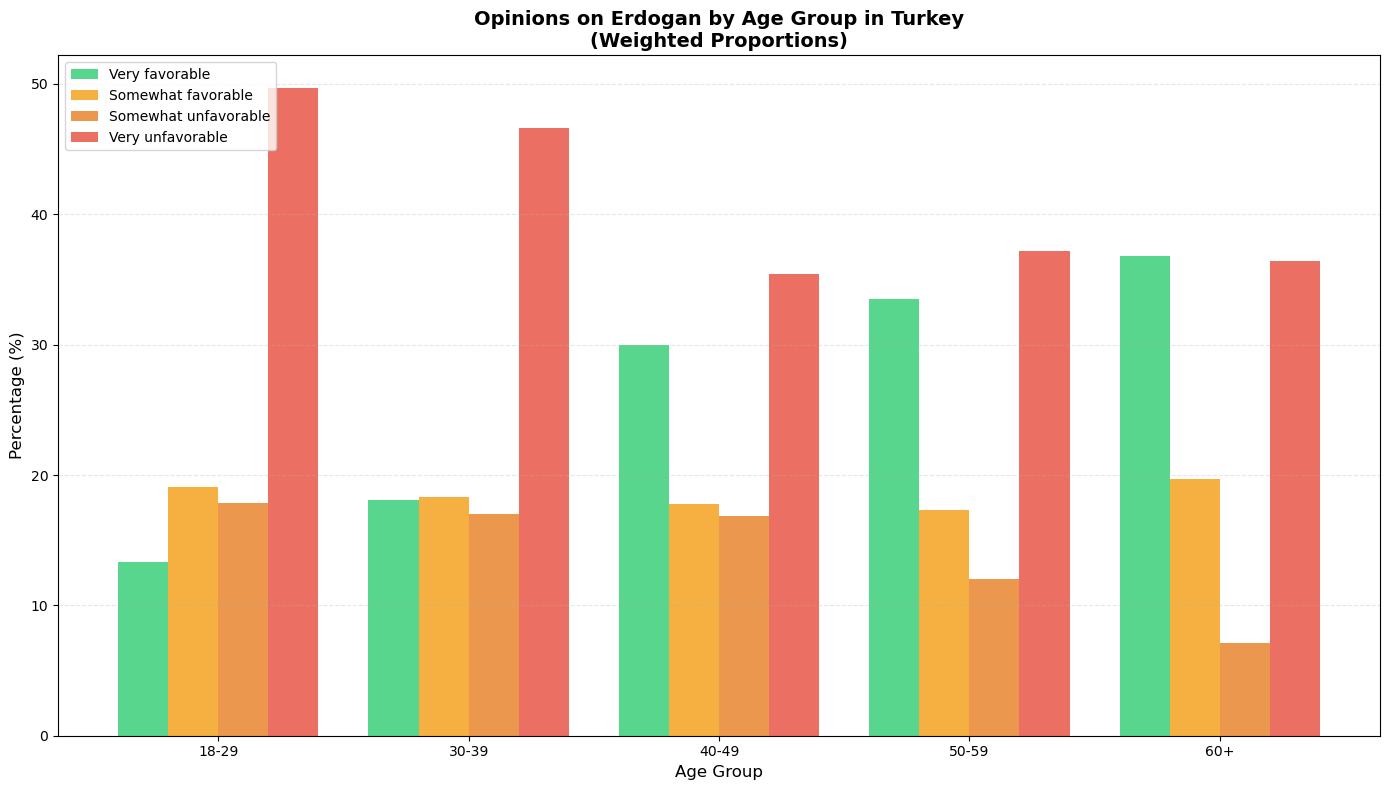

In [29]:
# Filter to Turkey only
turkey_data = pew[pew['country_name'] == 'Turkey'].copy()

print(turkey_data['fav_erdogan'].value_counts().sort_index())

# Check age distribution
print("\nAge statistics:")
print(turkey_data['age'].describe())

valid_data = turkey_data[turkey_data['fav_erdogan'].isin(['1', '2', '3', '4'])].copy()
valid_data = valid_data.dropna(subset=['age', 'weight', 'fav_erdogan'])

# Check age distribution
print("\nAge statistics:")
print(turkey_data['age'].describe())

# Create age groups
def create_age_groups(age):
    if pd.isna(age):
        return None
    elif age < 30:
        return '18-29'
    elif age < 40:
        return '30-39'
    elif age < 50:
        return '40-49'
    elif age < 60:
        return '50-59'
    else:
        return '60+'

valid_data['age_group'] = valid_data['age'].apply(create_age_groups)

# Calculate weighted proportions by age group
age_groups = ['18-29', '30-39', '40-49', '50-59', '60+']
opinion_labels = {
    '1': 'Very favorable',
    '2': 'Somewhat favorable',
    '3': 'Somewhat unfavorable',
    '4': 'Very unfavorable'
}

# Calculate weighted proportions for each age group
results = {}
for age_group in age_groups:
    group_data = valid_data[valid_data['age_group'] == age_group]
    if len(group_data) > 0:
        total_weight = group_data['weight'].sum()
        weighted_counts = group_data.groupby('fav_erdogan')['weight'].sum()
        proportions = (weighted_counts / total_weight) * 100
        results[age_group] = proportions

# Display results
print("Weighted proportions by age group:")
for age_group in age_groups:
    if age_group in results:
        print(f"\n{age_group}:")
        for code in ['1', '2', '3', '4']:
            pct = results[age_group].get(code, 0)
            print(f"  {opinion_labels[code]}: {pct:.1f}%")

import matplotlib.pyplot as plt
import numpy as np

# Prepare data for plotting
category_codes = ['1', '2', '3', '4']
category_labels = ['Very favorable', 'Somewhat favorable', 
                   'Somewhat unfavorable', 'Very unfavorable']
colors = ['#2ecc71', '#f39c12', '#e67e22', '#e74c3c']

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(age_groups))
width = 0.2

for i, (code, label, color) in enumerate(zip(category_codes, category_labels, colors)):
    proportions = [results[ag].get(code, 0) if ag in results else 0 for ag in age_groups]
    offset = (i - 1.5) * width
    ax.bar(x + offset, proportions, width, label=label, color=color, alpha=0.8)

ax.set_xlabel('Age Group', fontsize=12)
ax.set_ylabel('Percentage (%)', fontsize=12)
ax.set_title("Opinions on Erdogan by Age Group in Turkey\n(Weighted Proportions)", 
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(age_groups)
ax.legend(loc='upper left')
ax.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

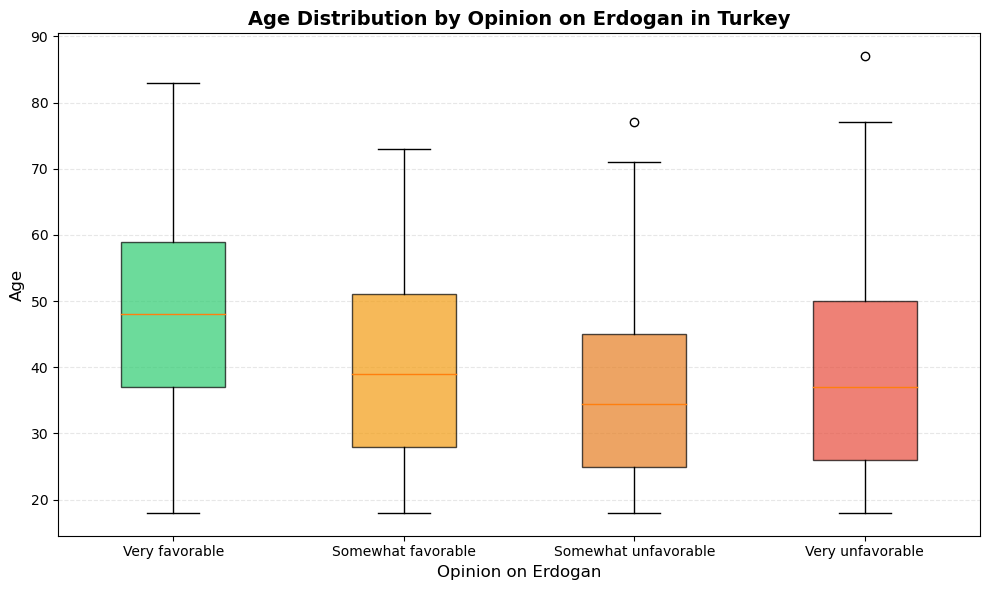

In [30]:
# Create box plot showing age distribution by opinion
fig, ax = plt.subplots(figsize=(10, 6))

# Prepare data for box plot
box_data = []
box_labels = []
for code in ['1', '2', '3', '4']:
    opinion_data = valid_data[valid_data['fav_erdogan'] == code]['age'].dropna()
    if len(opinion_data) > 0:
        box_data.append(opinion_data)
        box_labels.append(opinion_labels[code])

bp = ax.boxplot(box_data, labels=box_labels, patch_artist=True)
colors_box = ['#2ecc71', '#f39c12', '#e67e22', '#e74c3c']
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_ylabel('Age', fontsize=12)
ax.set_xlabel('Opinion on Erdogan', fontsize=12)
ax.set_title("Age Distribution by Opinion on Erdogan in Turkey", 
             fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

### China's influence on the global economy

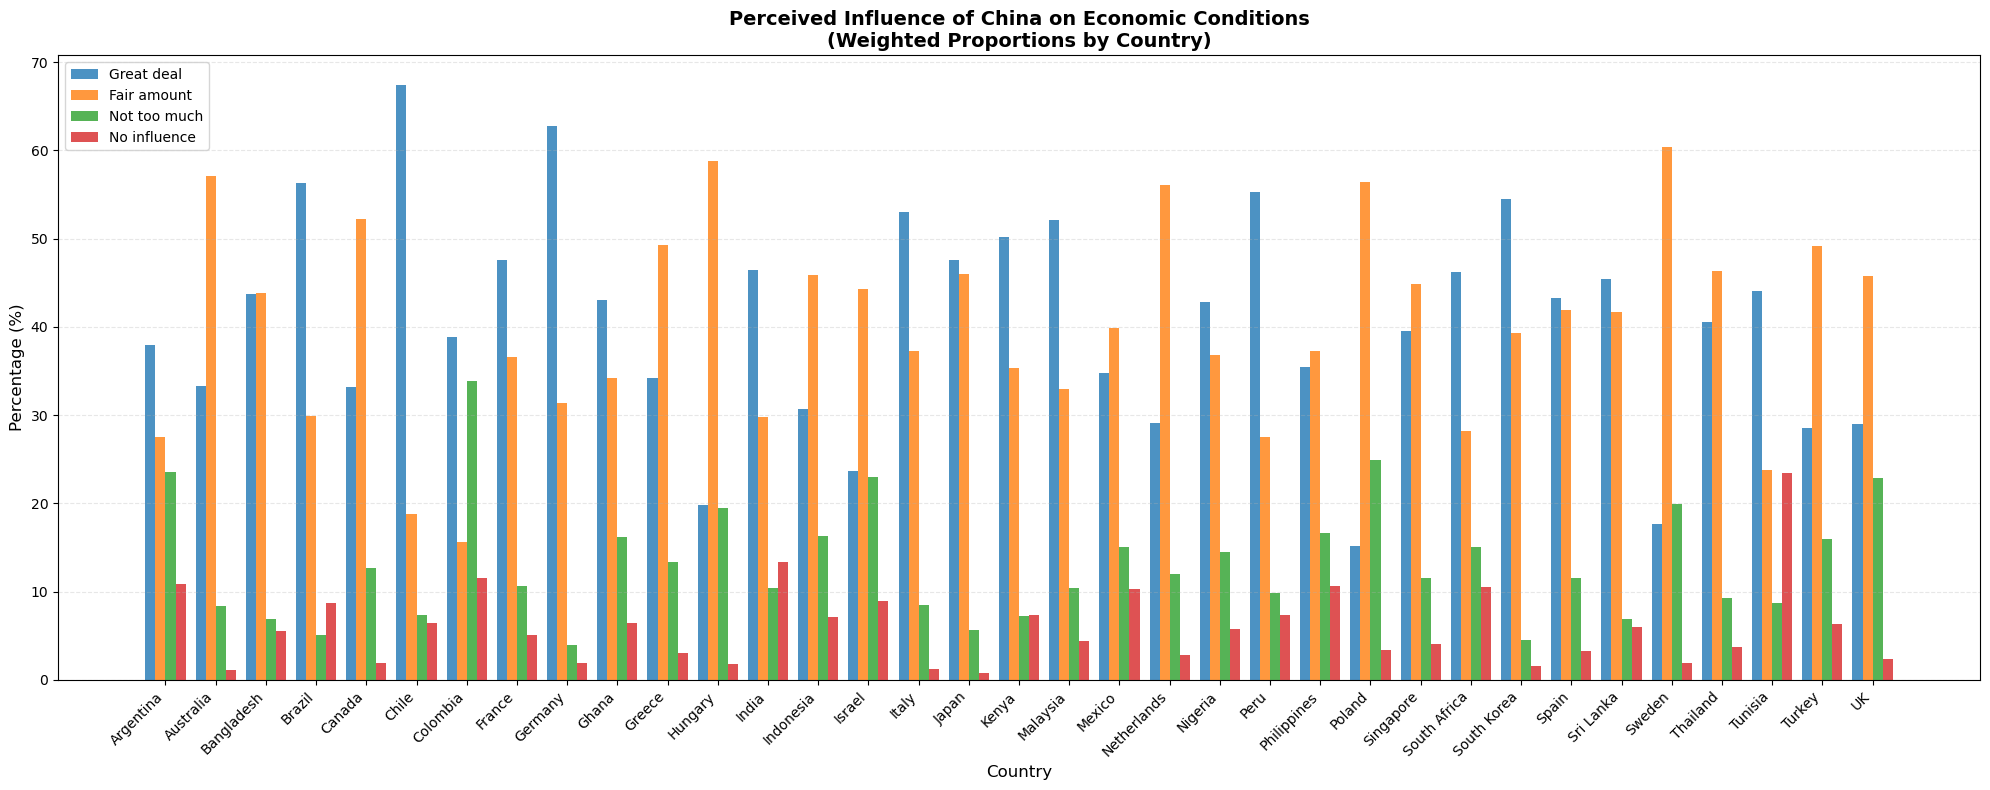

In [31]:
# Filter to valid responses (1-4) - exclude DK/Refused for cleaner visualization
valid_data = pew[pew['china_influ_econ'].isin(['1', '2', '3', '4'])].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name'])

# Calculate weighted proportions for each country
def calculate_weighted_proportions(df, var_name):
    """Calculate weighted proportions for a variable by country"""
    results = {}
    for country in df['country_name'].unique():
        country_data = df[df['country_name'] == country]
        total_weight = country_data['weight'].sum()
        weighted_counts = country_data.groupby(var_name)['weight'].sum()
        proportions = (weighted_counts / total_weight) * 100
        results[country] = proportions
    return results

# Get proportions for each country
country_proportions = calculate_weighted_proportions(valid_data, 'china_influ_econ')

# Prepare data for plotting
labels = {
    '1': 'Great deal',
    '2': 'Fair amount',
    '3': 'Not too much',
    '4': 'No influence'
}

countries = sorted(valid_data['country_name'].unique())
categories = ['Great deal', 'Fair amount', 'Not too much', 'No influence']

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(20, 8))

x = np.arange(len(countries))
width = 0.2  # Width of bars

# Create bars for each category
for i, (code, label) in enumerate([('1', 'Great deal'), ('2', 'Fair amount'), 
                                    ('3', 'Not too much'), ('4', 'No influence')]):
    proportions = [country_proportions[country].get(code, 0) for country in countries]
    offset = (i - 1.5) * width
    ax.bar(x + offset, proportions, width, label=label, alpha=0.8)

ax.set_xlabel('Country', fontsize=12)
ax.set_ylabel('Percentage (%)', fontsize=12)
ax.set_title("Perceived Influence of China on Economic Conditions\n(Weighted Proportions by Country)", 
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(countries, rotation=45, ha='right')
ax.legend(loc='upper left')
ax.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

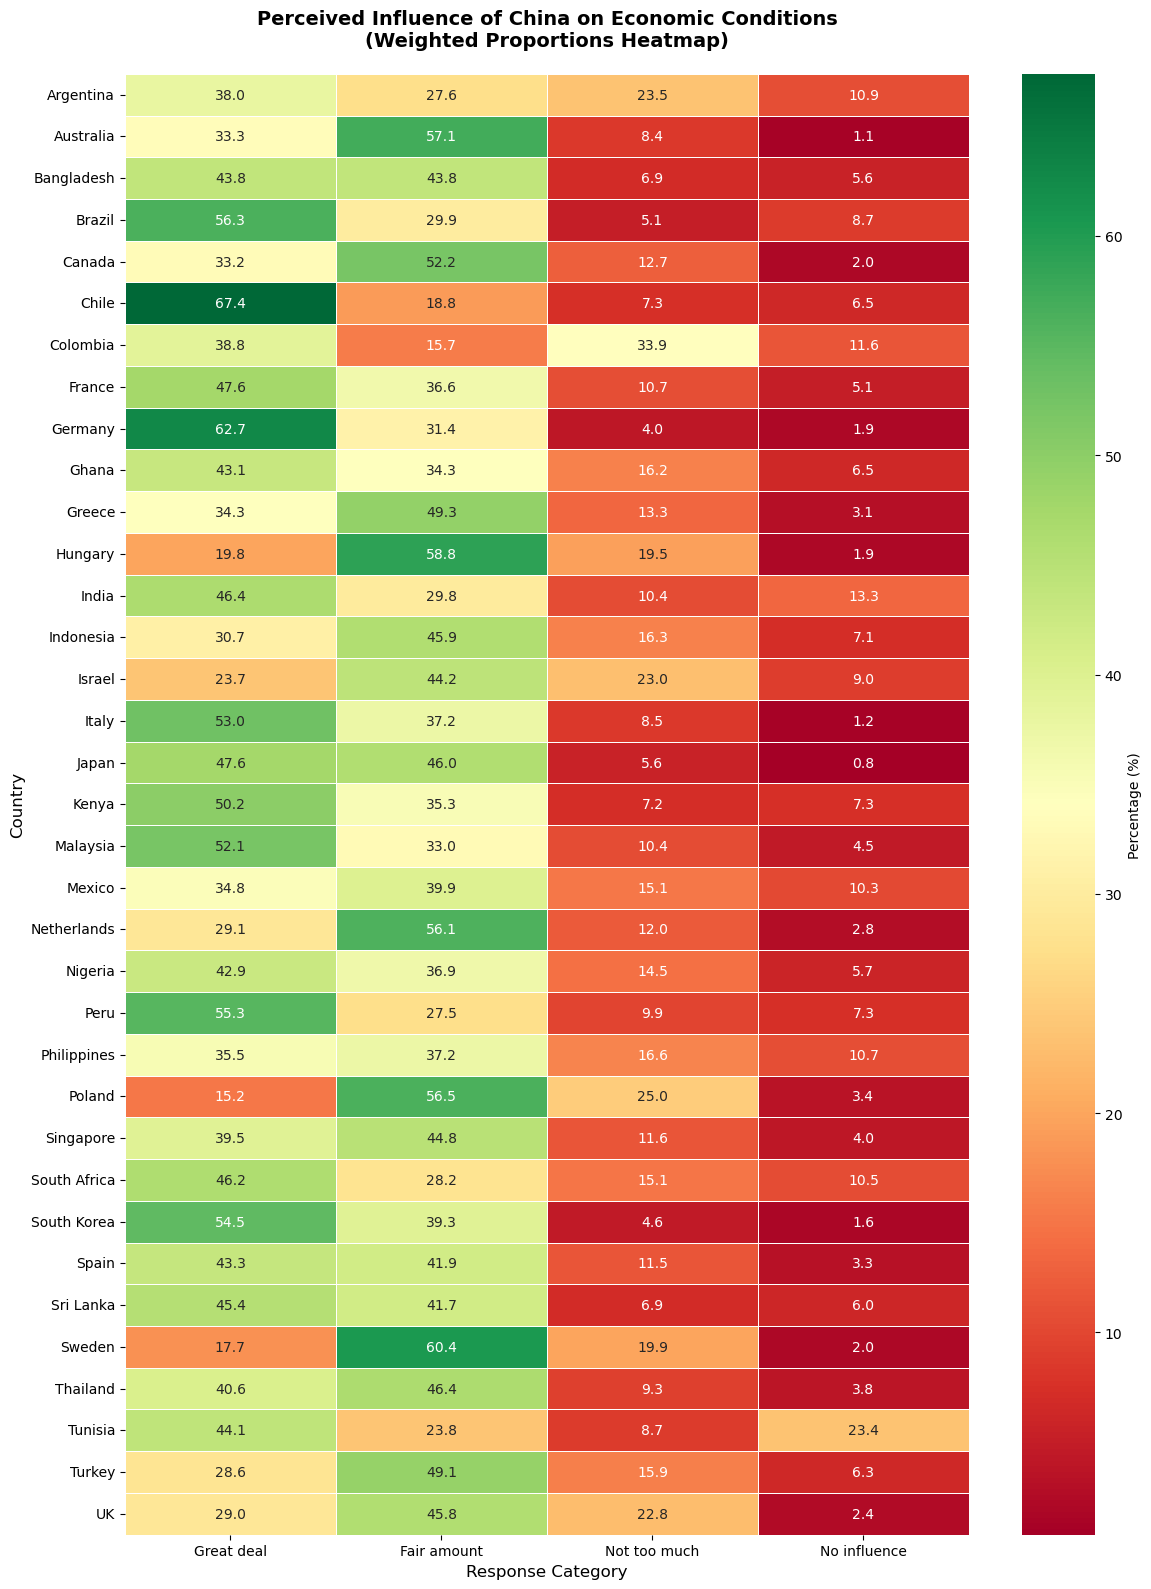

In [33]:
# Filter to valid responses (1-4) - exclude DK/Refused for cleaner visualization
valid_data = pew[pew['china_influ_econ'].isin(['1', '2', '3', '4'])].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name'])

# Calculate weighted proportions for each country
def calculate_weighted_proportions(df, var_name):
    """Calculate weighted proportions for a variable by country"""
    results = {}
    for country in df['country_name'].unique():
        country_data = df[df['country_name'] == country]
        total_weight = country_data['weight'].sum()
        weighted_counts = country_data.groupby(var_name)['weight'].sum()
        proportions = (weighted_counts / total_weight) * 100
        results[country] = proportions
    return results

# Get proportions for each country
country_proportions = calculate_weighted_proportions(valid_data, 'china_influ_econ')

# Prepare data for heatmap
countries = sorted(valid_data['country_name'].unique())
category_codes = ['1', '2', '3', '4']
category_labels = ['Great deal', 'Fair amount', 'Not too much', 'No influence']

# Create matrix for heatmap
heatmap_data = []
for country in countries:
    row = [country_proportions[country].get(code, 0) for code in category_codes]
    heatmap_data.append(row)

heatmap_df = pd.DataFrame(heatmap_data, 
                          index=countries, 
                          columns=category_labels)

# Create heatmap
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(12, 16))
sns.heatmap(heatmap_df, annot=True, fmt='.1f', cmap='RdYlGn', 
            cbar_kws={'label': 'Percentage (%)'}, ax=ax, linewidths=0.5)
ax.set_title("Perceived Influence of China on Economic Conditions\n(Weighted Proportions Heatmap)", 
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Response Category', fontsize=12)
ax.set_ylabel('Country', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# Filter to valid responses (1-4) and ensure weight is numeric
valid_data = pew[pew['internet_freedom'].isin(['1', '2', '3', '4'])].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'internet_freedom'])

# Calculate weighted proportions for each country
country_proportions = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Calculate weighted counts for each response category
    weighted_counts = country_data.groupby('internet_freedom')['weight'].sum()
    proportions = (weighted_counts / total_weight) * 100
    
    country_proportions[country] = {
        '1': proportions.get('1', 0),  # Very important
        '2': proportions.get('2', 0),  # Somewhat important
        '3': proportions.get('3', 0),  # Not too important
        '4': proportions.get('4', 0)   # Not important at all
    }

# Create a summary: % who say internet freedom is important (1 or 2) vs not important (3 or 4)
summary_stats = {}
for country, props in country_proportions.items():
    important_percent = props['1'] + props['2']  # Very + Somewhat important
    not_important_percent = props['3'] + props['4']  # Not too + Not at all important
    summary_stats[country] = {
        'Important': important_percent,
        'Not Important': not_important_percent
    }

# Convert to DataFrame for easier visualization
summary_df = pd.DataFrame(summary_stats).T
summary_df = summary_df.sort_values('Important', ascending=False)

print("Summary: Percentage who believe internet freedom is IMPORTANT vs NOT IMPORTANT")
print("=" * 75)
print(summary_df.round(1))

Summary: Percentage who believe internet freedom is IMPORTANT vs NOT IMPORTANT
              Important  Not Important
Sweden             96.1            3.9
Hungary            93.7            6.3
Poland             93.4            6.6
Netherlands        92.8            7.2
Greece             92.6            7.4
Canada             91.1            8.9
Germany            90.8            9.2
Spain              90.2            9.8
UK                 89.8           10.2
Argentina          89.6           10.4
Chile              89.2           10.8
South Korea        88.8           11.2
Turkey             88.4           11.6
Australia          88.3           11.7
Italy              88.3           11.7
Thailand           87.4           12.6
Mexico             84.8           15.2
Ghana              84.6           15.4
France             84.1           15.9
Indonesia          83.8           16.2
Japan              83.5           16.5
Brazil             82.2           17.8
Malaysia           81.8 

In [ ]:
# Filter to valid responses (1-4) and ensure weight is numeric
valid_data = pew[pew['internet_freedom'].isin(['1', '2', '3', '4'])].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'internet_freedom'])

# Calculate weighted proportions for each country
country_proportions = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Calculate weighted counts for each response category
    weighted_counts = country_data.groupby('internet_freedom')['weight'].sum()
    proportions = (weighted_counts / total_weight) * 100
    
    country_proportions[country] = {
        '1': proportions.get('1', 0),  # Very important
        '2': proportions.get('2', 0),  # Somewhat important
        '3': proportions.get('3', 0),  # Not too important
        '4': proportions.get('4', 0)   # Not important at all
    }

# Create a summary: % who say internet freedom is important (1 or 2) vs not important (3 or 4)
summary_stats = {}
for country, props in country_proportions.items():
    important_percent = props['1'] + props['2']  # Very + Somewhat important
    not_important_percent = props['3'] + props['4']  # Not too + Not at all important
    summary_stats[country] = {
        'Important': important_percent,
        'Not Important': not_important_percent
    }

# Convert to DataFrame for easier visualization
summary_df = pd.DataFrame(summary_stats).T
summary_df = summary_df.sort_values('Important', ascending=False)

print("Summary: Percentage who believe internet freedom is IMPORTANT vs NOT IMPORTANT")
print("=" * 75)
print(summary_df.round(1))

Summary: Percentage who believe internet freedom is IMPORTANT vs NOT IMPORTANT
              Important  Not Important
Sweden             96.1            3.9
Hungary            93.7            6.3
Poland             93.4            6.6
Netherlands        92.8            7.2
Greece             92.6            7.4
Canada             91.1            8.9
Germany            90.8            9.2
Spain              90.2            9.8
UK                 89.8           10.2
Argentina          89.6           10.4
Chile              89.2           10.8
South Korea        88.8           11.2
Turkey             88.4           11.6
Australia          88.3           11.7
Italy              88.3           11.7
Thailand           87.4           12.6
Mexico             84.8           15.2
Ghana              84.6           15.4
France             84.1           15.9
Indonesia          83.8           16.2
Japan              83.5           16.5
Brazil             82.2           17.8
Malaysia           81.8 

In [ ]:
# See how many respondents per country
print("Respondents per country:")
print(pew['country_name'].value_counts().sort_index())

# See the distribution
print(f"\nTotal respondents: {len(pew)}")
print(f"Total countries: {pew['country_name'].nunique()}")
print(f"Average respondents per country: {len(pew) / pew['country_name'].nunique():.0f}")

# when aggregating across countries, we should use the weight column.

Respondents per country:
country_name
Argentina       1017
Australia       2021
Bangladesh      1046
Brazil          1054
Canada          1163
Chile           1020
Colombia        1051
France          1018
Germany         1008
Ghana           1035
Greece          1015
Hungary          996
India           3559
Indonesia        937
Israel          1001
Italy           1120
Japan           1003
Kenya           1049
Malaysia        1005
Mexico          1042
Netherlands     1010
Nigeria         1050
Peru            1050
Philippines     1011
Poland          1031
Singapore       1014
South Africa    1524
South Korea     1029
Spain           1013
Sri Lanka       2519
Sweden          1017
Thailand        1000
Tunisia         1009
Turkey          1049
UK              1017
Name: count, dtype: int64

Total respondents: 41503
Total countries: 35
Average respondents per country: 1186


In [23]:
pew['age'].notna().sum()

39482

In [5]:
pew["id"].nunique() 

41503

In [37]:
pew["free_speech"].unique() 

array(['1', '2', '3', '4', '9', '8', ' '], dtype=object)

In [6]:
pew["weight"].nunique() 

21297

In [7]:
pew["fav_japan"].nunique() # each 

7

In [8]:
pew["fav_japan"].unique() 

array([' ', '2', '4', '1', '3', '8', '9'], dtype=object)

In [10]:
len(pew)  

41503

In [12]:
# Basic shape & a peek
pew.head(3)
print(*pew.columns[:40], sep="\n")  # scan first 40 names

survey
country
weight
id
econ_sit
children_betteroff
satisfied_democracy
fav_us
fav_china
fav_eu
fav_un
fav_nato
fav_russia
fav_brazil
fav_india
fav_bangladesh
fav_srilanka
fav_pakistan
fav_japan
fav_lula
fav_bolsonaro
fav_netanyahu
fav_lapid
fav_bengvir
fav_gantz
fav_gallant
fav_abbas
fav_smotrich
fav_erdogan
fav_kilicdaroglu
fav_pope
partyfav_argentina_cambiemos
partyfav_argentina_fdt
partyfav_argentina_avanza
partyfav_australia_labor
partyfav_australia_liberal
partyfav_australia_greens
partyfav_australia_onenation
partyfav_bangladesh_bal
partyfav_bangladesh_bnp


In [13]:
# Basic dataset info
print("Dataset shape:", pew.shape)
print("\nTotal columns:", len(pew.columns))
print("\nTotal rows:", len(pew))
print("\nMemory usage:", pew.memory_usage(deep=True).sum() / 1024**2, "MB")

Dataset shape: (41503, 653)

Total columns: 653

Total rows: 41503

Memory usage: 1500.9995574951172 MB


In [14]:
# See all countries in the dataset
countries = pew['country'].unique()
print(f"Number of countries: {len(countries)}")
print("\nCountries:")
for i, country in enumerate(sorted(countries), 1):
    print(f"{i}. {country}")

Number of countries: 35

Countries:
1. 10
2. 11
3. 12
4. 13
5. 14
6. 15
7. 16
8. 17
9. 18
10. 19
11. 2
12. 20
13. 21
14. 22
15. 23
16. 24
17. 25
18. 26
19. 27
20. 28
21. 29
22. 3
23. 30
24. 31
25. 32
26. 33
27. 34
28. 35
29. 36
30. 4
31. 5
32. 6
33. 7
34. 8
35. 9
